# R1: Load the data and build the activity table

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

players = pd.read_csv("data/synthetic/synthetic_players.csv", parse_dates=["install_time"])
sessions = pd.read_csv("data/synthetic/synthetic_sessions.csv", parse_dates=["session_start"])
END = pd.Timestamp("2026-09-30") # last day of the data

#Which day after install was each session? (day 0 = install day)
s = sessions.merge(players[["player_id", "install_time"]], on="player_id")
s["day_n"] = (s["session_start"].dt.normalize() - s["install_time"].dt.normalize()).dt.days

# One row per player per day they played
activity = s[["player_id", "day_n"]].drop_duplicates()

# How many days after install we can observe each player before the data ends
players["days_observable"] = (END - players["install_time"].dt.normalize()).dt.days

print(len(players), "players |", len (activity), "player-days")
activity.head()

50000 players | 452278 player-days


,player_id,day_n
0,1,0
3,2,0
5,3,0
8,4,0
10,5,0


# R2: Classic retention (D1, D7, D30 and more)

In [2]:
def retention(n):
    # players we can observe for at least n days
    eligible = players.loc[players["days_observable"] >= n, "player_id"]
    # of those, how many played on day n
    returned = activity.loc[(activity["day_n"] == n) & activity["player_id"].isin(eligible), "player_id"].nunique()
    return returned / len(eligible), len(eligible)

rows = []
for n in [1, 3, 7, 14, 30, 60, 90]:
    r, base = retention(n)
    rows.append({"day": n, "retention_%": round(r * 100, 1), "eligible_players": base})
retention_table = pd.DataFrame(rows)
retention_table

,day,retention_%,eligible_players
0,1,35.4,49920
1,3,22.1,49757
2,7,14.9,49411
3,14,10.6,48859
4,30,6.2,47550
5,60,3.9,45103
6,90,3.1,42677


In [3]:
for n in [30, 90]:
    naive = activity.loc[activity["day_n"] == n, "player_id"].nunique() / len(players)
    print(f"D{n}  correct: {retention(n)[0]:.1%}   naive (all players): {naive:.1%}")

D30  correct: 6.2%   naive (all players): 5.9%
D90  correct: 3.1%   naive (all players): 2.6%


# R3: The retention curve

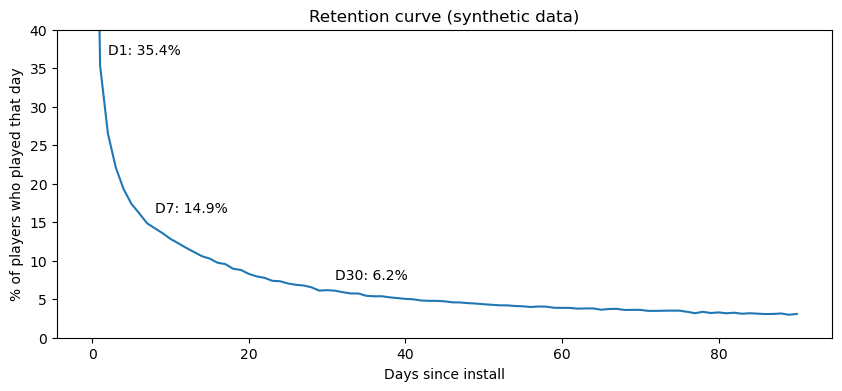

In [4]:
days = range(0, 91)
curve = pd.Series({n: retention(n)[0] * 100 for n in days})

ax = curve.plot(figsize=(10, 4), title="Retention curve (synthetic data)")
for n in [1, 7, 30]:
    ax.annotate(f"D{n}: {curve[n]:.1f}%", (n, curve[n]),
                textcoords="offset points", xytext=(6, 8))
ax.set_xlabel("Days since install")
ax.set_ylabel("% of players who played that day")
ax.set_ylim(0, 40)
plt.show()

# R4: Retention by install month (cohorts)

In [5]:
players["cohort"] = players["install_time"].dt.to_period("M")

cohort_rows = []
for cohort, grp in players.groupby("cohort"):
    row = {"cohort": str(cohort), "installs": len(grp)}
    for n in [1, 7, 30]:
        # only fill in a value if EVERY player in the cohort can be observed for n days
        if (grp["days_observable"] < n).any():
            row[f"D{n}"] = None
            continue
        ret = activity.loc[(activity["day_n"] == n) & activity["player_id"].isin(grp["player_id"]),
                           "player_id"].nunique() / len(grp)
        row[f"D{n}"] = round(ret * 100, 1)
    cohort_rows.append(row)

cohorts = pd.DataFrame(cohort_rows).set_index("cohort")
cohorts.style.background_gradient(cmap="Blues", subset=["D1", "D7", "D30"]).format(precision=1, na_rep="")

,installs,D1,D7,D30
cohort,,,,
2025-04,2449,35.9,15.0,5.4
2025-05,4602,33.8,12.9,5.1
2025-06,3174,35.9,15.3,7.5
2025-07,2625,35.1,15.2,6.8
2025-08,2533,36.4,15.7,7.1
2025-09,2915,35.4,16.0,6.7
2025-10,2579,37.2,15.4,5.9
2025-11,2397,35.8,16.1,5.8
2025-12,2563,36.0,14.8,6.2


# R5: Test whether event players really retain worse

In [6]:
from statsmodels.stats.proportion import proportions_ztest, proportion_confint

# Players who installed within 3 weeks after a big release (dates from palia_events.csv)
BIG_RELEASES = ["2025-05-13", "2026-05-12"]
players["event_window"] = False
for d in BIG_RELEASES:
    start = pd.Timestamp(d)
    players.loc[(players["install_time"] >= start) &
                (players["install_time"] < start + pd.Timedelta(days=21)), "event_window"] = True

rows = []
for n in [1, 7, 30]:
    elig = players[players["days_observable"] >= n].copy()
    elig["returned"] = elig["player_id"].isin(activity.loc[activity["day_n"] == n, "player_id"])
    g = elig.groupby("event_window")["returned"].agg(["sum", "count"])

    # two-proportion z-test: are the two retention rates different?
    z, p = proportions_ztest([g.loc[True, "sum"], g.loc[False, "sum"]],
                             [g.loc[True, "count"], g.loc[False, "count"]])
    for flag, label in [(True, "event window"), (False, "normal")]:
        k, total = g.loc[flag, "sum"], g.loc[flag, "count"]
        lo, hi = proportion_confint(k, total, method="wilson")
        rows.append({"day": f"D{n}", "group": label, "players": total,
                     "retention_%": round(k / total * 100, 1),
                     "95%_CI": f"{lo*100:.1f} - {hi*100:.1f}", "p_value": f"{p:.1e}"})
event_table = pd.DataFrame(rows)
event_table

,day,group,players,retention_%,95%_CI,p_value
0,D1,event window,7101,33.0,31.9 - 34.1,4.7e-06
1,D1,normal,42819,35.8,35.3 - 36.2,4.7e-06
2,D7,event window,7101,12.2,11.5 - 13.0,1.7e-11
3,D7,normal,42310,15.3,15.0 - 15.7,1.7e-11
4,D30,event window,7101,4.5,4.1 - 5.1,6.8e-10
5,D30,normal,40449,6.5,6.2 - 6.7,6.8e-10


In [7]:
elig = players[players["days_observable"] >= 30].copy()
elig["returned_d30"] = elig["player_id"].isin(activity.loc[activity["day_n"] == 30, "player_id"])
elig["install_day"] = elig["install_time"].dt.normalize()

per_day = elig.groupby("event_window").agg(days=("install_day", "nunique"),
                                           installs=("player_id", "count"),
                                           retained_d30=("returned_d30", "sum"))
per_day["installs_per_day"] = (per_day["installs"] / per_day["days"]).round(1)
per_day["d30_players_per_day"] = (per_day["retained_d30"] / per_day["days"]).round(1)
per_day

,days,installs,retained_d30,installs_per_day,d30_players_per_day
event_window,,,,,
False,476,40449,2613,85.0,5.5
True,42,7101,323,169.1,7.7


# R6: Churn: who leaves, and when?

In [8]:
CHURN_DAYS = 14

# last day each player was active (days since install)
last_day = activity.groupby("player_id")["day_n"].max()
players["last_active_day"] = players["player_id"].map(last_day)

# only players observed for at least 14 days can be classified
players["classifiable"] = players["days_observable"] >= CHURN_DAYS
players["churned"] = players["classifiable"] & \
    ((players["days_observable"] - players["last_active_day"]) >= CHURN_DAYS)

c = players[players["classifiable"]]
print(f"Classifiable players: {len(c)} | churned: {c['churned'].sum()} ({c['churned'].mean():.1%}) "
      f"| still active: {(~c['churned']).sum()}")

# When did churned players play for the last time?
when = pd.cut(c.loc[c["churned"], "last_active_day"], bins=[-1, 0, 1, 7, 30, 90, 10_000],
              labels=["install day only", "day 1", "days 2-7", "days 8-30", "days 31-90", "after day 90"])
(when.value_counts(normalize=True).sort_index() * 100).round(1)

Classifiable players: 48859 | churned: 47591 (97.4%) | still active: 1268


last_active_day
install day only    47.0
day 1               12.2
days 2-7            19.7
days 8-30           13.6
days 31-90           4.5
after day 90         3.0
Name: proportion, dtype: float64

# R7: Summary of findings

## Summary: retention and churn (synthetic data)

**Note:** this notebook uses synthetic data modeled on Palia. The results demonstrate
the methods; the underlying behavior was set by benchmark-based assumptions.

### Findings
1. **Retention:** D1 35.4%, D7 14.9%, D30 6.2%, in line with top-tier PC games
   (GameAnalytics benchmarks). The steepest drop happens in the first days, followed by
   a long, stable tail of committed players.
2. **Churn timing:** 97% of players eventually churn (no play for 14+ days), which is
   typical for free-to-play over 18 months. 47% never return after their install day,
   and about 79% of churners leave within the first week.
3. **Event cohorts:** players who installed within 3 weeks after a big release retain
   significantly worse (D30 4.5% vs 6.5%, p < 0.001).
4. **But releases still pay off:** event days bring twice as many installs, so they
   produce more long-term players per day (7.7 vs 5.5 still active at D30).

### Methods worth noting
- **Eligibility:** retention on day n only counts players observable for at least n days.
  Ignoring this understated D90 by 16% (2.6% vs 3.1%).
- **Noise:** monthly cohorts vary by about ±1 point by chance alone, so differences
  were tested (two-proportion z-test, 95% Wilson confidence intervals) before drawing conclusions.
- **Churn definition:** 14 consecutive days without play; players observed for fewer than
  14 days were excluded as not classifiable.

### Implications
- The first session matters most: improving onboarding would reduce the largest loss.
- Judge releases by retained players in absolute numbers, not only by retention rate.

### Limitations
- Synthetic data: no weekly play rhythm, and the "event tourist" effect was planted to
  demonstrate detection (the 21-day window used in the analysis matches the generator).
- Benchmarks come partly from mobile studies; PC/console behavior may differ.

In [9]:
import os
OUT = "data/powerbi"
os.makedirs(OUT, exist_ok=True)

# 1. Retention curve, day 0-90, for all players and for event vs normal players
def retention_for(n, mask):
    eligible = players.loc[mask & (players["days_observable"] >= n), "player_id"]
    returned = activity.loc[(activity["day_n"] == n) & activity["player_id"].isin(eligible), "player_id"].nunique()
    return round(returned / len(eligible) * 100, 2)

groups = {"All players":  pd.Series(True, index=players.index),
          "Event window": players["event_window"],
          "Normal":       ~players["event_window"]}
curve = pd.DataFrame([{"day": n, "group": g, "retention_pct": retention_for(n, m)}
                      for g, m in groups.items() for n in range(0, 91)])
curve.to_csv(f"{OUT}/retention_curve.csv", index=False)

# 2. Cohort table, in "long" format (one row per cohort and retention day)
cohorts.reset_index().melt(id_vars=["cohort", "installs"], value_vars=["D1", "D7", "D30"],
                           var_name="retention_day", value_name="retention_pct") \
       .to_csv(f"{OUT}/retention_cohorts.csv", index=False)

# 3. Event vs normal comparison with confidence intervals
event_table.to_csv(f"{OUT}/retention_event_vs_normal.csv", index=False)

# 4. When churners left
(when.value_counts(normalize=True).sort_index() * 100).round(1) \
    .rename_axis("last_active").reset_index(name="share_of_churners_pct") \
    .to_csv(f"{OUT}/churn_timing.csv", index=False)

print("Saved:", sorted(os.listdir(OUT)))

Saved: ['churn_timing.csv', 'retention_cohorts.csv', 'retention_curve.csv', 'retention_event_vs_normal.csv']


In [10]:
pd.read_csv("data/powerbi/retention_curve.csv").head(10)

,day,group,retention_pct
0,0,All players,100.00
1,1,All players,35.36
2,2,All players,26.52
3,3,All players,22.13
4,4,All players,19.31
5,5,All players,17.39
6,6,All players,16.16
7,7,All players,14.87
8,8,All players,14.21
9,9,All players,13.57
